# Tunable optical binding between two levitated nanoparticles (after Rieser et al. 2022)

J. Rieser, M. A. Ciampini, H. Rudolph, N. Kiesel, K. Hornberger, B. A. Stickler, M. Aspelmeyer and
U. Delić, *Tunable light-induced dipole-dipole interaction between optically levitated
nanoparticles*, Science **377**, 987 (2022), [doi:10.1126/science.abp9941](https://doi.org/10.1126/science.abp9941)
(parameters taken from the arXiv version, arXiv:2203.04198v2, main text and supplementary material).

Two silica spheres sit in two phase-coherent tweezers a distance $d_0$ apart along $x$, polarised
along $y$. Each particle scatters its tweezer's light; the scattered light interferes with the other
tweezer at the other particle, and the interference couples the motions. The coupling oscillates with
the separation (period $\lambda$), falls as $1/d_0$ (far field), and is tuned by the relative optical
phase $\Delta\phi_0 = \phi_1 - \phi_2$: $\Delta\phi_0 = 0, \pi$ give a conservative (reciprocal) coupling,
other phases add a non-conservative (anti-reciprocal) part (their Eq. (1)).

This notebook builds the system with levisim's `OpticalBinding` interaction in a `MultiTrap`
(`interactions=[OpticalBinding()]`) and compares:

1. the coupling rate $g/\Omega'$ against the separation for $\Delta\phi_0 = 0$ and $\pi$ (their Fig. 3a and
   the quoted values at $d_0$ = 3.15 μm and 2.2 μm),
2. the avoided crossing of the normal modes against the power imbalance $\eta$ (Fig. 2),
3. the dependence on the optical phase at $d_0$ = 3.2 μm (Fig. 3c) and the non-conservative rate at
   $d_0$ = 2.2 μm, $\Delta\phi_0 = 0.8\pi$ (Fig. 3b),
4. the $x$ coupling at 2.2 μm (Fig. S3) and the suppression by the polarisation angle (Fig. 4b).

**What levisim models.** Point dipoles in levisim's paraxial Gaussian tweezers, with the full
free-space dipole field (near, intermediate and far terms), the Gouy phase and the radiation
reaction in the polarisability. The binding force is computed separately on each particle (no
Newton's third law is assumed). The paper's fits add two effects that are not modelled here: the Airy
tails of the high-NA foci, which interfere with the scattered light, and the displacement of the
particles by the static binding force (their supplementary "Interaction model used for fitting").

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt

from levisim.core.constants import π, ε0
from levisim.core.units import kHz, mW, nm, μm
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.physics import Bead, Tweezer, OpticalBinding
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.covariance import quadrature_matrices

set_plt_rcParams_to_xmgrace_style()
logger.remove()  # the scans build many systems
T_START = time.time()

λ = 1064 * nm
k = 2 * π / λ
R = 105 * nm           # radius 105 ± 3 nm (main text)
P = 400 * mW           # total trapping power 2P ≈ 800 mW, split as P(1 ± η) (main text)
w0 = 730 * nm          # trap waist ≈ 730 nm (supplementary, experimental setup)


def binding_pair(d0, Δφ0, η=0.0, r=R, axis=(1, 0, 0), order='first'):
    """Two traps d0 apart along `axis`; φ1 - φ2 = Δφ0; powers P(1 ± η); beads at the cavity node
    (so the cavity, which MultiTrap always has, does not act; the analysis drops it: cavity=False)"""
    tweezers = [Tweezer(Power=P * (1 + η), λ=λ, wx0=w0, wy0=w0), Tweezer(Power=P * (1 - η), λ=λ, wx0=w0, wy0=w0)]
    beads = [Bead(r=r, Φ=π/2), Bead(r=r, Φ=π/2)]
    return MultiTrap(
        num_traps=2, Cartesian_axes_per_trap=3, tweezers=tweezers, beads=beads,
        trap_positions=[(0, 0, 0), tuple(d0 * np.asarray(axis, dtype=float))],
        φn_dict={1: Δφ0, 2: 0.0}, interactions=[OpticalBinding(order=order)], static_cavity_shifts=False,
    )


def rates(mtrap, axis='z'):
    """(g, ḡ, Ω') of the two `axis` modes: g ± ḡ are the rates of particle 2 → 1 and 1 → 2
    (Rieser Eq. (1)); Ω' is the mean of the two shifted frequencies"""
    labels, G = mtrap.labels, mtrap.mechanical_coupling_matrix
    g12 = G[labels.index(f'{axis}1'), labels.index(f'{axis}2')]
    g21 = G[labels.index(f'{axis}2'), labels.index(f'{axis}1')]
    Ω = 0.5 * (mtrap.dimensions[f'{axis}1'].Ω + mtrap.dimensions[f'{axis}2'].Ω)
    return (g12 + g21) / 2, (g12 - g21) / 2, Ω


def z_eigenvalues(mtrap):
    """Eigenvalues of the mechanical drift (no cavity) restricted to z1, z2 (levisim's full linear
    drift, no rotating-wave approximation)"""
    A, _ = quadrature_matrices(mtrap, cavity=False)
    labels = mtrap.labels
    index = [i for label in ('z1', 'z2') for i in (2 * labels.index(label), 2 * labels.index(label) + 1)]
    eig = np.linalg.eigvals(A[np.ix_(index, index)])
    eig = eig[eig.imag > 0]
    return eig[np.argsort(eig.imag)]


single = binding_pair(20 * μm, 0.0).traps[0]
print(f'levisim trap frequencies (paraxial Gaussian, P = {P/mW:.0f} mW, w0 = {w0/nm:.0f} nm): '
      f'Ωz/2π = {single.Ωj["z"]/kHz:.1f} kHz, Ωx/2π = {single.Ωj["x"]/kHz:.1f} kHz '
      f'(measured: 51 kHz and ≈ 4 × 51 kHz)')
print(f'mass {single.bead.m*1e18:.2f} fg (paper 7.0 ± 0.7 fg); Rayleigh range zR = {single.tweezer.zR/μm:.3f} μm')

levisim trap frequencies (paraxial Gaussian, P = 400 mW, w0 = 730 nm): Ωz/2π = 80.6 kHz, Ωx/2π = 245.8 kHz (measured: 51 kHz and ≈ 4 × 51 kHz)
mass 8.97 fg (paper 7.0 ± 0.7 fg); Rayleigh range zR = 1.573 μm


## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| wavelength | 1064 nm | main text |
| radius | 105 ± 3 nm (silica, levisim's default material) | main text |
| power per trap | $P$ = 400 mW, split as $P(1\pm\eta)$ | main text ("total trapping power of $2P \sim$ 800 mW") |
| waist | 730 nm (both axes) | supplementary, *Experimental setup* |
| separation | $d_0$ = 2.0-3.8 μm along $x$ | Figs. 2, 3 |
| polarisation | along $y$ (levisim's tweezer polarisation), $\Theta$ rotates the separation axis instead | Fig. 1c, Fig. 4a |

**Frequency scale.** levisim's paraxial Gaussian trap gives $\Omega_z/2\pi \approx$ 80 kHz at these
parameters, against the measured 51 kHz (the NA = 0.8 focus is not a paraxial Gaussian). The paper
expresses its couplings as $g/\Omega'$, which it notes does not depend on the power. In levisim this
ratio $g/\Omega' = k_1/(2m\Omega'^2)$ is the ratio of the binding stiffness to the trap stiffness, both
$\propto E_0^2$, so it depends only on the polarisability, wavelength, waist and separation. The
comparisons below are therefore made in these ratios; absolute frequencies in kHz are levisim's.

**Sign conventions.** levisim's `mechanical_coupling_matrix[j, k]` is the rate at which dimension $k$
drives $j$. Rieser's Eq. (1) has $z_1$ driven by $(k_1 + k_2)z_2$, so $g + \bar g$ = `G[z1, z2]` and
$g - \bar g$ = `G[z2, z1]`, with $g = k_1/(2m\Omega)$ in both conventions ($H/\hbar \ni -g\,q_1q_2$). The
phase is the tweezer's `Tweezer.φ` (field $\propto e^{i\phi}$ with $E(t) = \mathrm{Re}[E e^{-i\omega t}]$),
$\Delta\phi_0 = \phi_1 - \phi_2$; with this choice the signs of $k_1$ and $k_2$ come out as in their Eq. (1)
(tested against their far-field expressions in `tests/test_optical_binding.py`).

## 1. Coupling against separation (Fig. 3a)

Published values compared (stated before computing): $g/\Omega' = \pm(0.09 \pm 0.01)$ at
$d_0 \approx$ 3.15 μm for $\Delta\phi_0 = 0$ and $\pi$ (main text, Fig. 2), and the largest coupling
$g/\Omega' = 0.186 \pm 0.017$ at $d_0 \approx$ 2.2 μm, $\Delta\phi_0 = 0$ (main text). The paper's fits are good for
$d_0 \gtrsim$ 2.4 μm; below that it lists missing near-field and trap-shape effects.

d0 = 3.15 μm, Δφ0 = 0π: g/Ω' = +0.0876 (r = 102-108 nm: +0.0815 to +0.0939)
d0 = 3.15 μm, Δφ0 = 1π: g/Ω' = -0.1360 (r = 102-108 nm: -0.1518 to -0.1217)
d0 = 2.20 μm, Δφ0 = 0π: g/Ω' = +0.1076 (r = 102-108 nm: +0.1008 to +0.1145)
d0 = 2.20 μm, Δφ0 = 1π: g/Ω' = -0.1909 (r = 102-108 nm: -0.2138 to -0.1705)
self-consistent / first order at 2.2 μm: 1.0004


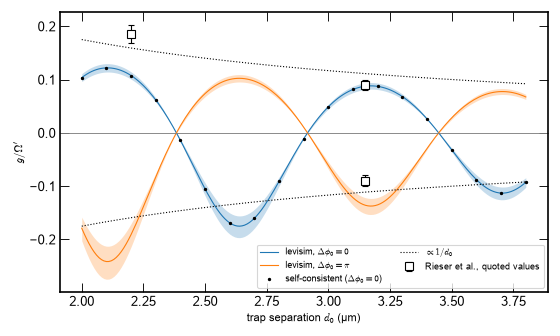

In [ ]:
separations = np.linspace(2.0, 3.8, 181) * μm
curves = {}
for Δφ0 in (0.0, π):
    for r in (R - 3 * nm, R, R + 3 * nm):
        curves[(Δφ0, r)] = np.array([rates(binding_pair(d0, Δφ0, r=r))[0] / rates(binding_pair(d0, Δφ0, r=r))[2]
                                     for d0 in separations])
sc = np.array([rates(m)[0] / rates(m)[2] for m in (binding_pair(d0, 0.0, order='self_consistent') for d0 in separations[::10])])

quoted = {}
for d0, Δφ0 in ((3.15 * μm, 0.0), (3.15 * μm, π), (2.2 * μm, 0.0), (2.2 * μm, π)):
    values = [rates(binding_pair(d0, Δφ0, r=r))[0] / rates(binding_pair(d0, Δφ0, r=r))[2] for r in (R - 3*nm, R, R + 3*nm)]
    quoted[(d0, Δφ0)] = values
    print(f'd0 = {d0/μm:.2f} μm, Δφ0 = {Δφ0/π:.0f}π: g/Ω\' = {values[1]:+.4f} (r = 102-108 nm: {min(values):+.4f} to {max(values):+.4f})')
first_22 = curves[(0.0, R)][np.argmin(abs(separations - 2.2 * μm))]
print(f'self-consistent / first order at 2.2 μm: {sc[2] / first_22:.4f}')

fig, ax = plt.subplots(figsize=(7, 4.2))
for Δφ0, colour, name in ((0.0, 'C0', r'$\Delta\phi_0 = 0$'), (π, 'C1', r'$\Delta\phi_0 = \pi$')):
    ax.fill_between(separations / μm, curves[(Δφ0, R - 3*nm)], curves[(Δφ0, R + 3*nm)], color=colour, alpha=0.25, lw=0)
    ax.plot(separations / μm, curves[(Δφ0, R)], color=colour, label=f'levisim, {name}')
ax.plot(separations[::10] / μm, sc, 'k.', ms=4, label='self-consistent ($\\Delta\\phi_0 = 0$)')
ax.errorbar([3.15, 3.15, 2.2], [0.09, -0.09, 0.186], yerr=[0.01, 0.01, 0.017], fmt='s', color='k', mfc='w',
            capsize=3, label='Rieser et al., quoted values')
envelope = abs(curves[(0.0, R)]).max() * separations.min() / separations
ax.plot(separations / μm, envelope, 'k:', lw=1, label=r'$\propto 1/d_0$')
ax.plot(separations / μm, -envelope, 'k:', lw=1)
ax.axhline(0, color='0.5', lw=0.8)
ax.set_xlabel(r'trap separation $d_0$ (μm)')
ax.set_ylabel(r"$g/\Omega'$")
ax.legend(fontsize=8, ncol=2, loc='lower right')
fig.tight_layout()

The coupling oscillates with period $\lambda$ and falls as $1/d_0$, as measured. Two features need a
comment. (i) $|g/\Omega'|$ is larger for $\Delta\phi_0 = \pi$ than for 0 at the same separation, because
levisim adds each particle's own binding stiffness to its trap ($\Omega'^2 = \Omega^2 + k_1/m$, Rudolph et
al.'s Eq. (9)): attractive binding ($g < 0$) softens the traps and raises $g/\Omega'$. (ii) The paper's
zero crossings for the two phases are not mirror images (its supplementary attributes this to the
static binding force moving the particles); levisim linearises at the trap foci, so its crossings
are those of $\cos kd_0$ at the foci.

## 2. Avoided crossing against the power imbalance (Fig. 2)

Published: at $d_0 \approx$ 3.15 μm the breathing mode is displaced from the CoM mode by
$2g/2\pi \approx$ 8 kHz at $\eta = 0$ (on $\Omega/2\pi \approx$ 51 kHz), upwards for $\Delta\phi_0 = 0$ and downwards for
$\pi$. In units of the frequency this is $2g/\Omega \approx 0.16$.

Δφ0 = 0π: minimum splitting (Ω- - Ω+)/Ω_tw = 0.1940; 2g/Ω_tw = 0.1933; CoM mode at η = 0: 1.0016 Ω_tw
Δφ0 = 1π: minimum splitting (Ω- - Ω+)/Ω_tw = 0.2431; 2g/Ω_tw = 0.2408; CoM mode at η = 0: 0.9984 Ω_tw


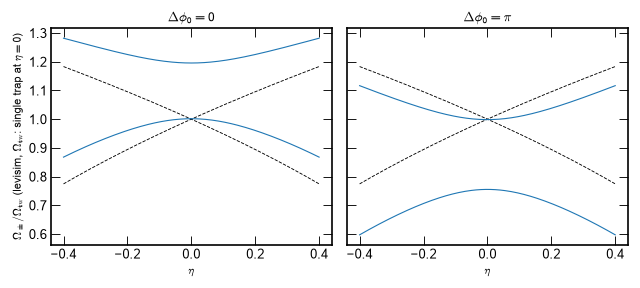

In [ ]:
ηs = np.linspace(-0.4, 0.4, 161)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), sharey=True)
for ax, Δφ0, title in zip(axes, (0.0, π), (r'$\Delta\phi_0 = 0$', r'$\Delta\phi_0 = \pi$')):
    Ω_ref = binding_pair(20 * μm, 0.0).traps[0].Ωj['z']
    freqs = np.array([z_eigenvalues(binding_pair(3.15 * μm, Δφ0, η=η)).imag for η in ηs]) / Ω_ref
    bare = np.array([[t.Ωj['z'] for t in binding_pair(3.15 * μm, Δφ0, η=η).traps] for η in ηs]) / Ω_ref
    ax.plot(ηs, bare, 'k--', lw=0.8)
    ax.plot(ηs, freqs, 'C0')
    ax.set_title(title)
    ax.set_xlabel(r'$\eta$')
    i0 = np.argmin(abs(ηs))
    split = np.min(np.diff(freqs, axis=1))
    g, _, Ωp = rates(binding_pair(3.15 * μm, Δφ0))
    print(f'Δφ0 = {Δφ0/π:.0f}π: minimum splitting (Ω- - Ω+)/Ω_tw = {split:.4f}; 2g/Ω_tw = {2*abs(g)/Ω_ref:.4f}; '
          f'CoM mode at η = 0: {freqs[i0].min() if Δφ0 == 0 else freqs[i0].max():.4f} Ω_tw')
axes[0].set_ylabel(r'$\Omega_\pm/\Omega_\mathrm{tw}$ (levisim, $\Omega_\mathrm{tw}$: single trap at $\eta = 0$)')
fig.tight_layout()

## 3. Optical phase: phase scan at 3.2 μm (Fig. 3c) and the non-conservative point (Fig. 3b)

Published: at $d_0 \approx$ 3.2 μm the splitting $(\Omega_- - \Omega_+)/2\Omega'$ follows the linear model near
$\Delta\phi_0 = n\pi$ and crosses zero near $\Delta\phi_0 \approx 0.8\pi$; the paper says that its own linear model
fails to describe the scan away from $n\pi$ (the motion is amplified, explores nonlinear terms and the
particles are displaced). At $d_0 \approx$ 2.2 μm and $\Delta\phi_0 = 0.8\pi$ it estimates $g/\Omega \approx 0$ and
$\bar g/\Omega \approx -0.068$, with degenerate eigenfrequencies for $\eta \in [0, 0.07]$.

zero crossings of g (levisim, linear, at the foci): [0.508 1.508] π
d0 = 2.2 μm, Δφ0 = 0.8π: g/Ω' = -0.1445, ḡ/Ω' = +0.0553 (paper: g ≈ 0, ḡ ≈ -0.068)
no η with degenerate eigenfrequencies in [-0.1, 0.2]


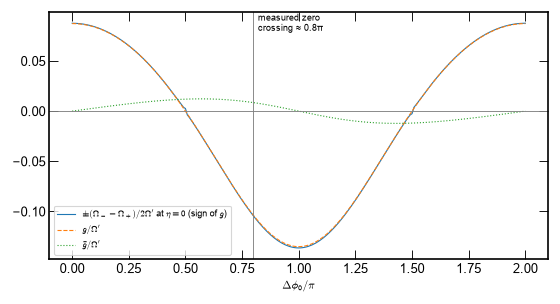

In [ ]:
phases = np.linspace(0, 2 * π, 241)
split, gs, gbars = [], [], []
for Δφ0 in phases:
    mt = binding_pair(3.2 * μm, Δφ0)
    ev = z_eigenvalues(mt)
    g, gbar, Ωp = rates(mt)
    split.append((ev[1].imag - ev[0].imag) / (2 * Ωp))
    gs.append(g / Ωp)
    gbars.append(gbar / Ωp)
split, gs, gbars = map(np.array, (split, gs, gbars))
signed = np.where(np.array(gs) >= 0, 1, -1) * split
crossings = phases[1:][np.diff(np.sign(gs)) != 0]
print('zero crossings of g (levisim, linear, at the foci):', np.round(crossings / π, 3), 'π')
mt = binding_pair(2.2 * μm, 0.8 * π)
g, gbar, Ωp = rates(mt)
print(f'd0 = 2.2 μm, Δφ0 = 0.8π: g/Ω\' = {g/Ωp:+.4f}, ḡ/Ω\' = {gbar/Ωp:+.4f} (paper: g ≈ 0, ḡ ≈ -0.068)')
degenerate = [η for η in np.linspace(-0.1, 0.2, 301) if np.ptp(z_eigenvalues(binding_pair(2.2 * μm, 0.8 * π, η=η)).imag)
              < 1e-3 * Ωp]
print(f'degenerate eigenfrequencies for η in [{min(degenerate):.3f}, {max(degenerate):.3f}]' if degenerate
      else 'no η with degenerate eigenfrequencies in [-0.1, 0.2]')

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(phases / π, signed, 'C0', label=r"$\pm(\Omega_- - \Omega_+)/2\Omega'$ at $\eta = 0$ (sign of $g$)")
ax.plot(phases / π, gs, 'C1--', label=r"$g/\Omega'$")
ax.plot(phases / π, gbars, 'C2:', label=r"$\bar g/\Omega'$")
ax.axvline(0.8, color='0.5', lw=0.8)
ax.text(0.82, 0.08, 'measured zero\ncrossing ≈ 0.8π', fontsize=8)
ax.axhline(0, color='0.5', lw=0.8)
ax.set_xlabel(r'$\Delta\phi_0/\pi$')
ax.legend(fontsize=8)
fig.tight_layout()

## 4. Motion along $x$ (Fig. S3) and the polarisation angle (Fig. 4)

Published: $g_x/\Omega_x' = 0.013 \pm 0.002$ at $d_0 \approx$ 2.2 μm (supplementary, Fig. S3). Rotating the
polarisation by $\Theta$ from $y$ scales the far-field coupling by $\cos^2\Theta$ (measured, Fig. 4b); at
$\Theta = 90°$ only the near field remains, estimated at $g/\Omega' \approx 6\times10^{-4}$ at $d_0 \sim 3\lambda$
(their Eq. (S9) and text). levisim's tweezers are polarised along $y$, so the polarisation angle is
applied by rotating the separation axis by $-\Theta$ about $z$, which is the same geometry.

gx/Ωx' at 2.2 μm, Δφ0 = 0: +0.0158 (paper 0.013 ± 0.002); levisim Ωx/2π = 250 kHz
g/Ω' at Θ = 0: +0.0872; at Θ = 90°: +5.31e-04 (paper estimate ≈ 6e-4 at d0 ~ 3λ)
largest |g(Θ)/g(0) - cos²Θ| = 0.051
run time 7 s


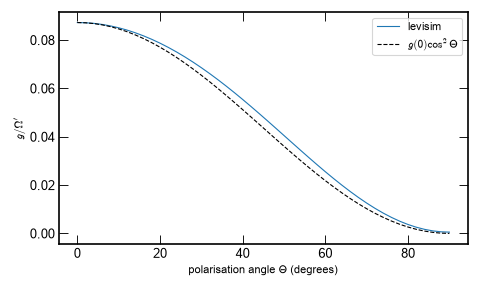

In [ ]:
gx, _, Ωx = rates(binding_pair(2.2 * μm, 0.0), axis='x')
print(f'gx/Ωx\' at 2.2 μm, Δφ0 = 0: {gx/Ωx:+.4f} (paper 0.013 ± 0.002); levisim Ωx/2π = {Ωx/kHz:.0f} kHz')
Θs = np.radians(np.linspace(0, 90, 46))
d_pol = 3.2 * μm
g_pol = np.array([rates(binding_pair(d_pol, 0.0, axis=(np.cos(Θ), -np.sin(Θ), 0)))[0]
                  / rates(binding_pair(d_pol, 0.0, axis=(np.cos(Θ), -np.sin(Θ), 0)))[2] for Θ in Θs])
print(f'g/Ω\' at Θ = 0: {g_pol[0]:+.4f}; at Θ = 90°: {g_pol[-1]:+.2e} (paper estimate ≈ 6e-4 at d0 ~ 3λ)')
print(f'largest |g(Θ)/g(0) - cos²Θ| = {np.max(abs(g_pol/g_pol[0] - np.cos(Θs)**2)):.3f}')
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(np.degrees(Θs), g_pol, 'C0', label='levisim')
ax.plot(np.degrees(Θs), g_pol[0] * np.cos(Θs)**2, 'k--', lw=1, label=r'$g(0)\cos^2\Theta$')
ax.set_xlabel(r'polarisation angle $\Theta$ (degrees)')
ax.set_ylabel(r"$g/\Omega'$")
ax.legend()
fig.tight_layout()
print(f'run time {time.time() - T_START:.0f} s')

## Summary

**Agreements with Rieser et al. (2022)**

- $g/\Omega'$ = +0.088 at $d_0$ = 3.15 μm, $\Delta\phi_0 = 0$ (0.082-0.094 for $r$ = 102-108 nm), against the
  measured +0.09 ± 0.01.
- The coupling oscillates with period $\lambda$ in $d_0$ and falls as $1/d_0$. Its sign follows $\cos kd_0\cos\Delta\phi_0$:
  repulsive at 3.15 μm for $\Delta\phi_0 = 0$ (the breathing mode moves up, the CoM mode stays at $\Omega$), and
  attractive for $\pi$.
- $g_x/\Omega_x'$ = 0.016 at 2.2 μm, against 0.013 ± 0.002 (1.4σ).
- The polarisation dependence follows $\cos^2\Theta$ to within 0.05 of $g(0)$; the difference is near-field
  terms. At $\Theta = 90°$, $g/\Omega' = 5.3\times10^{-4}$ against the paper's estimate of $\approx 6\times10^{-4}$.
- The self-consistent (multiple-scattering) coupling differs from the first-order one by 0.04 % at 2.2 μm,
  so the paper's second-order force is sufficient here.

**Differences and limits**

- The largest measured coupling, 0.186 ± 0.017 at 2.2 μm, is 1.7 times levisim's 0.108. The paper's own
  fit is good only above about 2.4 μm. Below that it lists the trap shape, the near field and the
  aerodynamic coupling as missing.
- At 3.15 μm and $\Delta\phi_0 = \pi$, levisim gives $-0.136$ against $-0.09 \pm 0.01$. levisim adds each particle's
  own binding stiffness to its trap, so attractive binding lowers $\Omega'$ and raises $|g|/\Omega'$. The
  measured values are symmetric.
- At 2.2 μm and $\Delta\phi_0 = 0.8\pi$, the paper estimates $g \approx 0$ and $\bar g/\Omega \approx -0.068$. levisim's linear model
  gives $g/\Omega' = -0.145$ and $\bar g/\Omega' = +0.055$. The magnitude of $\bar g$ is 19 % lower. Its sign
  follows their own Eq. (1) ($k_2 \propto \sin kd_0\sin\Delta\phi_0 > 0$ here), so the quoted negative value is
  probably a sign-convention difference. The linear $g$ vanishes at $\Delta\phi_0 = 0.51\pi$, not at the
  measured $\approx 0.8\pi$. The paper attributes that shift to nonlinear motion and to the displacement of the
  particles by the binding force, and states that its own linear model does not describe it either.
  Because $|g| > |\bar g|$ there, levisim finds no range of $\eta$ with degenerate eigenfrequencies; the
  paper measured degeneracy for $\eta \in [0, 0.07]$.
- Absolute frequencies differ: levisim's paraxial Gaussian trap gives $\Omega_z/2\pi$ = 80.6 kHz against the
  measured 51 kHz, and $\Omega_x/2\pi$ = 246 kHz against about 180-200 kHz. The ratios compared above do not
  depend on the power. The mass from levisim's silica density (8.97 fg) is above the paper's 7.0 ± 0.7 fg,
  but $g/\Omega'$ does not depend on the mass either.
- Not modelled: the Airy tails of the trapping fields and the static displacement of the particles,
  both of which the paper's fit includes, and the aerodynamic and electrostatic couplings (the latter
  is available as `Coulomb`).